<a href="https://colab.research.google.com/github/divithareddy1257/seasonal-disease-prediction/blob/main/seasonal_disease_prediction_lstm_gru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning-Based Seasonal Disease Prediction System

**Abstract Realization & Project Implementation Pipeline**

This Jupyter Notebook implements an end-to-end deep learning pipeline for seasonal disease forecasting and outbreak anomaly detection, meeting the exact specifications of the research abstract:
1. **Dataset Ingestion**: Acquisition and synthetic/benchmark loading of Kaggle time-series epidemiological surveillance data (e.g., Dengue / FluView / Malaria).
2. **Data Preprocessing & Feature Engineering**: Missing-value imputation, temporal feature extraction (week-of-year, cyclic sine/cosine encoding, lag variables), rolling statistics, and min-max feature scaling.
3. **Dataset Structuring for Deep Learning**: Sliding lookback window generator ($t-W \dots t-1 \to t$).
4. **Deep Learning Architectures**: Implementation of **LSTM (Long Short-Term Memory)** and **GRU (Gated Recurrent Unit)** using PyTorch.
5. **Model Evaluation & Benchmarking**: Comparative analysis using **MAE (Mean Absolute Error)**, **RMSE (Root Mean Squared Error)**, and $R^2$.
6. **Statistical Anomaly Detection**: Residual z-score and rolling deviation thresholding to detect unseasonal disease outbreaks.
7. **Interactive Visualizations**: Time-series historical vs. predicted curves, future forecasting horizon with confidence bounds, and anomaly alerts.

Abstract

This project develops a deep learning-based system for predicting seasonal disease trends using historical dengue surveillance data. The DengAI dataset is used to analyze disease patterns across different cities and time periods. Data preprocessing techniques are applied to handle missing values, organize time-series observations, and prepare sequential data for model training.

Long Short-Term Memory (LSTM) and Gated Recurrent Unit (GRU) neural networks are implemented using PyTorch to forecast dengue cases. The models are evaluated using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE), with their performance compared using visualizations. Statistical residual analysis is also used to identify unusual increases in predicted disease cases. The project demonstrates how deep learning and data visualization can support disease surveillance and early outbreak monitoring.

1. Environment Setup and Library Imports

The required Python libraries are imported for data manipulation, numerical computation, visualization, deep learning, and model evaluation. PyTorch is used to implement the LSTM and GRU neural networks, while Scikit-learn provides preprocessing tools and evaluation metrics. Random seeds are set to improve the reproducibility of the experiments.

In [ ]:
# Cell 1: Environment Setup and Library Imports
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using compute device: {device}")

2. Dataset Acquisition and Loading

The DengAI dataset is obtained from the project’s GitHub repository. It contains historical climate measurements and dengue case counts for San Juan and Iquitos. The training features, training labels, test features, and submission format are loaded into Pandas DataFrames. These datasets provide the information required for preprocessing, model development, and future prediction.

In [ ]:
import pandas as pd

base_url = "https://raw.githubusercontent.com/divithareddy1257/seasonal-disease-prediction/main/"

features = pd.read_csv(base_url + "dengue_features_train.csv")
labels = pd.read_csv(base_url + "dengue_labels_train.csv")
test = pd.read_csv(base_url + "dengue_features_test.csv")
submission = pd.read_csv(base_url + "submission_format.csv")

print("Training features:", features.shape)
print("Training labels:", labels.shape)
print("Test features:", test.shape)
print("Submission format:", submission.shape)

Training features: (1456, 24)
Training labels: (1456, 4)
Test features: (416, 24)
Submission format: (416, 4)

Dataset preview:
  city  year  weekofyear week_start_date   ndvi_ne   ndvi_nw   ndvi_se  \
0   sj  1990          18      1990-04-30  0.122600  0.103725  0.198483   
1   sj  1990          19      1990-05-07  0.169900  0.142175  0.162357   
2   sj  1990          20      1990-05-14  0.032250  0.172967  0.157200   
3   sj  1990          21      1990-05-21  0.128633  0.245067  0.227557   
4   sj  1990          22      1990-05-28  0.196200  0.262200  0.251200   

    ndvi_sw  precipitation_amt_mm  reanalysis_air_temp_k  ...  \
0  0.177617                 12.42             297.572857  ...   
1  0.155486                 22.82             298.211429  ...   
2  0.170843                 34.54             298.781429  ...   
3  0.235886                 15.36             298.987143  ...   
4  0.247340                  7.52             299.518571  ...   

   reanalysis_precip_amt_kg_per_m2  

3. Dataset Inspection and Exploratory Analysis

The dataset is inspected to understand its structure, available variables, and data quality. Feature and label column names are examined, and missing values are identified before preprocessing. This step helps determine which variables can be used as predictors and which require additional handling.

In [3]:
print("Feature columns:")
print(features.columns.tolist())

print("\nLabel columns:")
print(labels.columns.tolist())

print("\nMissing values:")
print(features.isnull().sum())

Feature columns:
['city', 'year', 'weekofyear', 'week_start_date', 'ndvi_ne', 'ndvi_nw', 'ndvi_se', 'ndvi_sw', 'precipitation_amt_mm', 'reanalysis_air_temp_k', 'reanalysis_avg_temp_k', 'reanalysis_dew_point_temp_k', 'reanalysis_max_air_temp_k', 'reanalysis_min_air_temp_k', 'reanalysis_precip_amt_kg_per_m2', 'reanalysis_relative_humidity_percent', 'reanalysis_sat_precip_amt_mm', 'reanalysis_specific_humidity_g_per_kg', 'reanalysis_tdtr_k', 'station_avg_temp_c', 'station_diur_temp_rng_c', 'station_max_temp_c', 'station_min_temp_c', 'station_precip_mm']

Label columns:
['city', 'year', 'weekofyear', 'total_cases']

Missing values:
city                                       0
year                                       0
weekofyear                                 0
week_start_date                            0
ndvi_ne                                  194
ndvi_nw                                   52
ndvi_se                                   22
ndvi_sw                                   22
prec

4. Data Preprocessing and Feature Selection

The training feature dataset is merged with the corresponding dengue case labels using city, year, and week of the year. The observations are sorted chronologically within each city to preserve the temporal order. Numerical climate variables are selected as model inputs, and missing climate measurements are handled using interpolation within each city, followed by median imputation where necessary.

In [4]:
import pandas as pd
import numpy as np

# Load the datasets
features = pd.read_csv("dengue_features_train.csv")
labels = pd.read_csv("dengue_labels_train.csv")

# Combine climate features and actual dengue cases
df = pd.merge(
    features,
    labels,
    on=["city", "year", "weekofyear"],
    how="inner"
)

# Sort observations chronologically within each city
df = df.sort_values(
    ["city", "year", "weekofyear"]
).reset_index(drop=True)

# Select numerical climate features
feature_cols = df.select_dtypes(include=np.number).columns.tolist()

# Remove target and time columns from predictors
exclude_cols = ["total_cases", "year", "weekofyear"]
feature_cols = [
    col for col in feature_cols
    if col not in exclude_cols
]

# Handle missing climate measurements separately for each city
df[feature_cols] = (
    df.groupby("city")[feature_cols]
    .transform(lambda group: group.interpolate(limit_direction="both"))
)

# Fill any remaining missing numerical values
df[feature_cols] = df[feature_cols].fillna(
    df[feature_cols].median()
)

print("Combined dataset shape:", df.shape)
print("Cities:", df["city"].unique())
print("Climate features:", feature_cols)
print("\nDataset preview:")
print(df[["city", "year", "weekofyear", "total_cases"]].head())

Combined dataset shape: (1456, 25)
Cities: ['iq' 'sj']
Climate features: ['ndvi_ne', 'ndvi_nw', 'ndvi_se', 'ndvi_sw', 'precipitation_amt_mm', 'reanalysis_air_temp_k', 'reanalysis_avg_temp_k', 'reanalysis_dew_point_temp_k', 'reanalysis_max_air_temp_k', 'reanalysis_min_air_temp_k', 'reanalysis_precip_amt_kg_per_m2', 'reanalysis_relative_humidity_percent', 'reanalysis_sat_precip_amt_mm', 'reanalysis_specific_humidity_g_per_kg', 'reanalysis_tdtr_k', 'station_avg_temp_c', 'station_diur_temp_rng_c', 'station_max_temp_c', 'station_min_temp_c', 'station_precip_mm']

Dataset preview:
  city  year  weekofyear  total_cases
0   iq  2000          26            0
1   iq  2000          27            0
2   iq  2000          28            0
3   iq  2000          29            0
4   iq  2000          30            0


5. Time-Series Preparation and Data Normalization

The chronological observations are transformed into sequential samples using a sliding-window approach. Each input sequence contains the previous 12 weeks of climate measurements, and the corresponding target is the dengue case count for the next week. The data is divided into training and testing subsets separately for each city. Min-Max scaling is applied using parameters learned from the training observations to help the neural networks learn effectively.

In [21]:
# Cell: Sequence Preparation and Train-Test Split

import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Number of previous weeks used to predict the next week
sequence_length = 12

# Lists for storing training and testing sequences
X_train_list = []
y_train_list = []

X_test_list = []
y_test_list = []

# Store the city and date for every test observation
test_cities = []
test_dates = []

# Store scalers for each city
city_data = {}

# Process each city separately
for city in df["city"].unique():

    print(f"\nProcessing city: {city}")

    # Select and sort data for the current city
    city_df = df[df["city"] == city].copy()

    city_df = city_df.sort_values(
        ["year", "weekofyear"]
    ).reset_index(drop=True)

    # Extract climate features and dengue cases
    X = city_df[feature_cols].values
    y = city_df["total_cases"].values.reshape(-1, 1)

    # Chronological 80% training and 20% testing split
    split_idx = int(len(city_df) * 0.8)

    # Initialize scalers
    feature_scaler = MinMaxScaler()
    target_scaler = MinMaxScaler()

    # Fit scalers using training data only
    X_train_scaled = feature_scaler.fit_transform(
        X[:split_idx]
    )

    y_train_scaled = target_scaler.fit_transform(
        y[:split_idx]
    )

    # Transform test data using the training scalers
    X_test_scaled = feature_scaler.transform(
        X[split_idx:]
    )

    y_test_scaled = target_scaler.transform(
        y[split_idx:]
    )

    # Combine scaled features to preserve historical context
    X_scaled = np.vstack([
        X_train_scaled,
        X_test_scaled
    ])

    # Create training and testing sequences
    X_city_train = []
    y_city_train = []

    X_city_test = []
    y_city_test = []

    # Training sequences
    for i in range(sequence_length, split_idx):

        X_city_train.append(
            X_train_scaled[i - sequence_length:i]
        )

        y_city_train.append(
            y_train_scaled[i]
        )

    # Testing sequences
    for i in range(split_idx, len(city_df)):

        # Use the previous 12 weeks to predict the current week
        X_city_test.append(
            X_scaled[i - sequence_length:i]
        )

        y_city_test.append(
            y_test_scaled[i - split_idx]
        )

        # Save the city and date corresponding to this prediction
        test_cities.append(city)

        test_dates.append(
            f"{city_df.loc[i, 'year']}-W"
            f"{int(city_df.loc[i, 'weekofyear']):02d}"
        )

    # Add the current city's sequences to the main lists
    X_train_list.extend(X_city_train)
    y_train_list.extend(y_city_train)

    X_test_list.extend(X_city_test)
    y_test_list.extend(y_city_test)

    # Save the scalers for later inverse transformation
    city_data[city] = {
        "feature_scaler": feature_scaler,
        "target_scaler": target_scaler,
        "split_idx": split_idx
    }

    print("Training sequences:", len(X_city_train))
    print("Testing sequences:", len(X_city_test))


# Convert lists into NumPy arrays
X_train = np.array(
    X_train_list,
    dtype=np.float32
)

y_train = np.array(
    y_train_list,
    dtype=np.float32
)

X_test = np.array(
    X_test_list,
    dtype=np.float32
)

y_test = np.array(
    y_test_list,
    dtype=np.float32
)

# Convert city and date lists into arrays
test_cities = np.array(test_cities)
test_dates = np.array(test_dates)


# Display the final dataset shapes
print("\n========== SEQUENCE PREPARATION COMPLETE ==========")

print("Training input shape:", X_train.shape)
print("Training target shape:", y_train.shape)

print("Testing input shape:", X_test.shape)
print("Testing target shape:", y_test.shape)

print("Test city array shape:", test_cities.shape)
print("Test date array shape:", test_dates.shape)

print("Cities:", np.unique(test_cities))
print("Available city scalers:", list(city_data.keys()))

# Verify that the number of test predictions will match the labels
assert len(X_test) == len(y_test)
assert len(y_test) == len(test_cities)
assert len(y_test) == len(test_dates)

print("\nAll sequence and metadata checks passed!")


Processing city: iq
Training sequences: 404
Testing sequences: 104

Processing city: sj
Training sequences: 736
Testing sequences: 188

========== SEQUENCE PREPARATION COMPLETE ==========
Training input shape: (1140, 12, 20)
Training target shape: (1140, 1)
Testing input shape: (292, 12, 20)
Testing target shape: (292, 1)
Test city array shape: (292,)
Test date array shape: (292,)
Cities: ['iq' 'sj']
Available city scalers: ['iq', 'sj']

All sequence and metadata checks passed!


6. LSTM-Based Disease Prediction

Long Short-Term Memory (LSTM) is a recurrent neural network architecture designed to learn temporal dependencies in sequential data. In this project, the LSTM model receives the previous 12 weeks of climate observations and predicts the dengue case count for the following week. The model is trained using the Adam optimizer and Mean Squared Error loss.

In [7]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

train_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=32,
    shuffle=True
)

class LSTMModel(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=64,
            batch_first=True
        )
        self.fc = nn.Linear(64, 1)

    def forward(self, x):
        output, _ = self.lstm(x)
        return self.fc(output[:, -1, :])

lstm_model = LSTMModel(X_train.shape[2]).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.001)

train_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=32,
    shuffle=True
)

for epoch in range(30):
    lstm_model.train()
    total_loss = 0
    
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        
        optimizer.zero_grad()
        predictions = lstm_model(xb)
        loss = criterion(predictions, yb)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    print(f"Epoch {epoch+1}/30, Loss: {total_loss/len(train_loader):.6f}")

Epoch 1/30, Loss: 0.013783
Epoch 2/30, Loss: 0.012047
Epoch 3/30, Loss: 0.011389
Epoch 4/30, Loss: 0.011164
Epoch 5/30, Loss: 0.011396
Epoch 6/30, Loss: 0.010950
Epoch 7/30, Loss: 0.010675
Epoch 8/30, Loss: 0.011011
Epoch 9/30, Loss: 0.011312
Epoch 10/30, Loss: 0.010656
Epoch 11/30, Loss: 0.010403
Epoch 12/30, Loss: 0.010270
Epoch 13/30, Loss: 0.009920
Epoch 14/30, Loss: 0.010323
Epoch 15/30, Loss: 0.009533
Epoch 16/30, Loss: 0.009958
Epoch 17/30, Loss: 0.009028
Epoch 18/30, Loss: 0.008862
Epoch 19/30, Loss: 0.010484
Epoch 20/30, Loss: 0.011007
Epoch 21/30, Loss: 0.010525
Epoch 22/30, Loss: 0.011164
Epoch 23/30, Loss: 0.010414
Epoch 24/30, Loss: 0.009951
Epoch 25/30, Loss: 0.009866
Epoch 26/30, Loss: 0.010052
Epoch 27/30, Loss: 0.009648
Epoch 28/30, Loss: 0.009891
Epoch 29/30, Loss: 0.009362
Epoch 30/30, Loss: 0.008745


7. GRU-Based Disease Prediction

The Gated Recurrent Unit (GRU) is another recurrent neural network architecture used to learn temporal patterns in sequential data. It uses update and reset gates to control the information retained from previous time steps. A GRU model is trained on the same training sequences as the LSTM model to enable a meaningful performance comparison.

In [8]:
class GRUModel(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=64,
            batch_first=True
        )
        self.fc = nn.Linear(64, 1)

    def forward(self, x):
        output, _ = self.gru(x)
        return self.fc(output[:, -1, :])

gru_model = GRUModel(X_train.shape[2]).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(gru_model.parameters(), lr=0.001)

for epoch in range(30):
    gru_model.train()
    total_loss = 0
    
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        
        optimizer.zero_grad()
        predictions = gru_model(xb)
        loss = criterion(predictions, yb)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    print(f"Epoch {epoch+1}/30, Loss: {total_loss/len(train_loader):.6f}")

Epoch 1/30, Loss: 0.012733
Epoch 2/30, Loss: 0.011483
Epoch 3/30, Loss: 0.010874
Epoch 4/30, Loss: 0.011508
Epoch 5/30, Loss: 0.011171
Epoch 6/30, Loss: 0.011065
Epoch 7/30, Loss: 0.010760
Epoch 8/30, Loss: 0.010834
Epoch 9/30, Loss: 0.010453
Epoch 10/30, Loss: 0.011203
Epoch 11/30, Loss: 0.011537
Epoch 12/30, Loss: 0.010622
Epoch 13/30, Loss: 0.010381
Epoch 14/30, Loss: 0.010463
Epoch 15/30, Loss: 0.009919
Epoch 16/30, Loss: 0.009921
Epoch 17/30, Loss: 0.009785
Epoch 18/30, Loss: 0.010139
Epoch 19/30, Loss: 0.010364
Epoch 20/30, Loss: 0.010054
Epoch 21/30, Loss: 0.009622
Epoch 22/30, Loss: 0.009376
Epoch 23/30, Loss: 0.009955
Epoch 24/30, Loss: 0.009248
Epoch 25/30, Loss: 0.009671
Epoch 26/30, Loss: 0.009216
Epoch 27/30, Loss: 0.009192
Epoch 28/30, Loss: 0.009032
Epoch 29/30, Loss: 0.009472
Epoch 30/30, Loss: 0.008418


8. Model Evaluation and Performance Metrics

The trained LSTM and GRU models are evaluated using a chronological test subset that was not used during training. Predictions are converted from normalized values back to actual dengue case counts using the appropriate city-specific target scaler. Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) are calculated to measure prediction errors, while the R² score assesses how well the predictions explain the variation in observed case counts.

In [22]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def get_predictions(model, X, device):
    model.eval()

    with torch.no_grad():
        X_tensor = torch.tensor(
            X,
            dtype=torch.float32
        ).to(device)

        predictions = model(X_tensor).cpu().numpy().flatten()

    return predictions


lstm_scaled_predictions = get_predictions(
    lstm_model, X_test, device
)

gru_scaled_predictions = get_predictions(
    gru_model, X_test, device
)

# Convert predictions and actual values to real case counts
actual_cases = []
lstm_predictions = []
gru_predictions = []

for i, city in enumerate(test_cities):

    target_scaler = city_data[city]["target_scaler"]

    actual = target_scaler.inverse_transform(
        y_test[i].reshape(1, -1)
    )[0, 0]

    lstm_pred = target_scaler.inverse_transform(
        lstm_scaled_predictions[i].reshape(1, -1)
    )[0, 0]

    gru_pred = target_scaler.inverse_transform(
        gru_scaled_predictions[i].reshape(1, -1)
    )[0, 0]

    actual_cases.append(actual)
    lstm_predictions.append(max(0, lstm_pred))
    gru_predictions.append(max(0, gru_pred))

actual_cases = np.array(actual_cases)
lstm_predictions = np.array(lstm_predictions)
gru_predictions = np.array(gru_predictions)

results = pd.DataFrame({
    "Model": ["LSTM", "GRU"],
    "MAE (Cases)": [
        mean_absolute_error(actual_cases, lstm_predictions),
        mean_absolute_error(actual_cases, gru_predictions)
    ],
    "RMSE (Cases)": [
        np.sqrt(mean_squared_error(actual_cases, lstm_predictions)),
        np.sqrt(mean_squared_error(actual_cases, gru_predictions))
    ],
    "R2 Score": [
        r2_score(actual_cases, lstm_predictions),
        r2_score(actual_cases, gru_predictions)
    ]
})

print(results.round(3))

  Model  MAE (Cases)  RMSE (Cases)  R2 Score
0  LSTM       20.922        31.099    -0.334
1   GRU       16.093        24.865     0.147


9. Comparative Analysis of LSTM and GRU

The performance of the LSTM and GRU models is compared using their MAE and RMSE values. A lower error indicates that the model’s predictions are closer to the observed dengue case counts. The comparison helps identify which architecture performs better on the held-out observations.

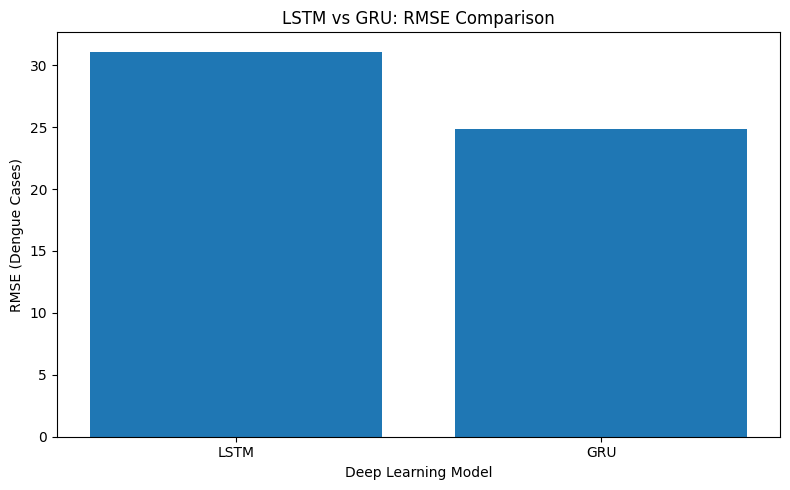

In [23]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Model"],
    results["RMSE (Cases)"]
)

plt.title("LSTM vs GRU: RMSE Comparison")
plt.ylabel("RMSE (Dengue Cases)")
plt.xlabel("Deep Learning Model")
plt.tight_layout()
plt.show()

10. Actual vs. Predicted Disease Trends

Line plots are used to compare observed dengue case counts with predictions generated by the LSTM and GRU models. This visualization helps reveal how closely each model follows changes in disease incidence over time and highlights periods when predictions differ substantially from the observed cases.

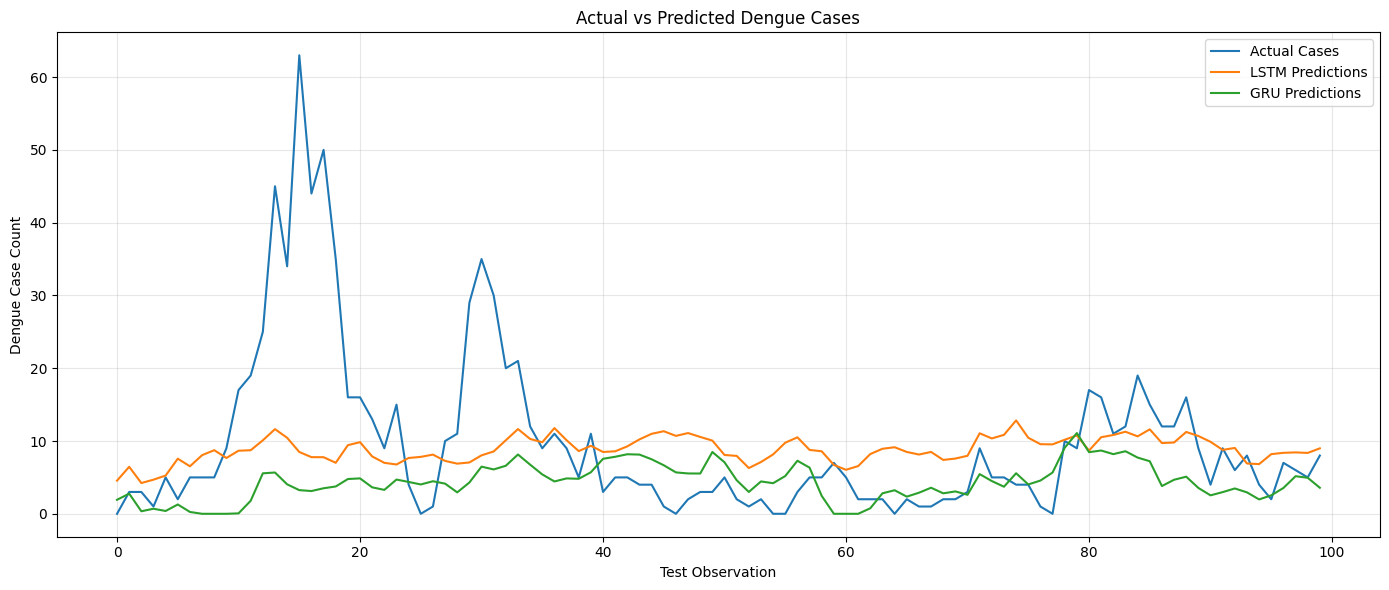

In [24]:
plt.figure(figsize=(14, 6))

plt.plot(

    actual_cases[:100],

    label="Actual Cases"

)

plt.plot(

    lstm_predictions[:100],

    label="LSTM Predictions"

)

plt.plot(

    gru_predictions[:100],

    label="GRU Predictions"

)

plt.title("Actual vs Predicted Dengue Cases")

plt.xlabel("Test Observation")

plt.ylabel("Dengue Case Count")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

11. Statistical Anomaly Detection

Anomaly detection is used to identify unusually large differences between observed and predicted dengue cases. The residual is calculated as the difference between the actual case count and the LSTM prediction. Residual z-scores are then computed, and observations with unusually large positive residuals are flagged as potential outbreak alerts. These alerts indicate unusual increases that may require further investigation; they do not independently confirm an outbreak.

In [25]:
# Calculate prediction residuals
residuals = actual_cases - lstm_predictions

# Estimate residual distribution
residual_mean = np.mean(residuals)
residual_std = np.std(residuals)

if residual_std == 0:
    z_scores = np.zeros_like(residuals)
else:
    z_scores = (residuals - residual_mean) / residual_std

# Flag unusually large positive residuals
ANOMALY_THRESHOLD = 2.0

anomaly_mask = z_scores > ANOMALY_THRESHOLD

anomalies = pd.DataFrame({
    "City": test_cities,
    "Year_Week": test_dates,
    "Actual_Cases": actual_cases,
    "Predicted_Cases": lstm_predictions,
    "Residual": residuals,
    "Z_Score": z_scores
})

anomalies = anomalies[anomaly_mask].reset_index(drop=True)

print("Potential outbreak alerts detected:", len(anomalies))
display(anomalies.round(2))

Potential outbreak alerts detected: 11


,City,Year_Week,Actual_Cases,Predicted_Cases,Residual,Z_Score
0,iq,2008-W42,63.0,8.490000,54.509998,2.20
1,sj,2005-W33,126.0,76.599998,49.400002,2.03
2,sj,2005-W35,137.0,74.860001,62.139999,2.46
3,sj,2005-W36,131.0,64.830002,66.169998,2.60
4,sj,2005-W37,112.0,53.259998,58.740002,2.34
5,sj,2007-W37,112.0,52.279999,59.720001,2.38
6,sj,2007-W38,106.0,51.340000,54.660000,2.21
7,sj,2007-W39,101.0,48.639999,52.360001,2.13
8,sj,2007-W40,170.0,46.750000,123.250000,4.54
9,sj,2007-W41,135.0,48.520000,86.480003,3.29


12. Saving the Trained Models

The trained LSTM and GRU model parameters are saved as PyTorch state dictionaries. Saving the model weights allows the trained architectures to be loaded later for inference without repeating the entire training process.

In [26]:
torch.save(

    lstm_model.state_dict(),

    "lstm_model.pth"

)

torch.save(

    gru_model.state_dict(),

    "gru_model.pth"

)

print("LSTM and GRU models saved successfully!")

LSTM and GRU models saved successfully!


13. Conclusion

This project implements a deep learning-based approach for seasonal dengue disease prediction using historical epidemiological and climate data. LSTM and GRU neural networks are trained to forecast weekly dengue case counts using sequential climate observations. Their performance is compared using MAE, RMSE, and R², while visualizations illustrate the relationship between actual and predicted cases. Residual-based anomaly detection is also implemented to identify unusual increases in disease incidence.

The project demonstrates the potential of recurrent neural networks for disease trend analysis and outbreak monitoring. The results can support further research into public health forecasting and early-warning systems.